# Model for aimpoint drift (aka ACA alignment drift) 2026-06

This notebook documents and computes fit coefficients for a simple model that
gives the relative ACA alignment as a linear function of the ACA CCD temperature.
It also includes validation of the new model against observed aimpoints.

## Summary

This is based on the `fit_aimpoint_drift-2025-03` notebook. One new jump was added.
All previous parameters are frozen; only the new jump amplitude is fitted for each axis.

The jump is fitted at `2025:182` (when the persistent offset was first observed) for
validation against historical data.  The deployed model uses `2026:161` so that the
correction applies only to observations scheduled from deployment onward.

The key fit results are:
```
DY
-----
new jump: +1.41 arcsec (fit at 2025:182, deployed at 2026:161)
model error = +/- 2.2 arcsec (1st to 99th percentile range = 4.47 arcsec)

DZ
-----
new jump: +0.47 arcsec (fit at 2025:182, deployed at 2026:161)
model error = +/- 2.3 arcsec (1st to 99th percentile range = 4.55 arcsec)
```

### Details

The ACA alignment is measured accurately for each science observation via the apparent
positions of the fid lights.  These are referred to by their CXC aspect solution
designation as the SIM DY and DZ offsets.  This is actually a misnomer based on
the pre-launch understanding of what physical mechanism would generate such offsets.
We now know via HRMA optical axis measurements that a temperature-dependent change 
in the ACA boresight alignment is responsible.  The HRMA to SIM alignment is quite
stable.

The ACA alignment relates directly to the X-ray detector aimpoint that is used in
observation planning and analysis.  With this model it will be possible to improve
the aimpoint accuracy by introducing a dynamic pointing offset based on the
predicted ACA CCD temperature for each observation.

The model is
```
DY/Z = (t_ccd - offset) * scale + (year - 2016.0) * trend + JUMPS
```
where
```
  t_ccd : ACA CCD temperature (degF)
  scale : scaling in arcsec / degF
  offset : ACA CCD temperature corresponding to DY/Z = 0.0 arcsec
  trend : Trend in DY/Z (arcsec / year)
  year : decimal year
  jumpYYYYDDD : step function from 0.0 to jumpYYYYDDD (arcsec) for date > YYYY:DDD
```

The jumps are persistent step function changes in alignment that have been observed following
extended dwells at normal sun where the ACA gets substantially hotter than during
normal operations.  The exact mechanism is not understood, but could be due to
a non-linear stiction release of a stress point that impacts alignment.

Note that the ACA alignment has a direct linear correlation to the ACA housing temperature (AACH1T).
However, in this model we use the ACA CCD temperature as the model dependent variable because it
is linearly related to housing temperature (AACCDPT = m * AACH1T + b) as long as the TEC is at
max drive current. Since there is already
an existing Xija model to predict ACA CCD temperature this reduces duplication.

*This notebook lives in the **aimpoint_mon** project repository*

## Setup

In [1]:
import json
import os
from pathlib import Path
from typing import List, Optional

import astropy.table as tbl
import astropy.units as u
import cheta.fetch_eng as fetch
import matplotlib.pyplot as plt
import numpy as np
import tables
from astropy.table import Table
from chandra_aca import drift
from cheta import fetch_sci
from cxotime import CxoTime
from kadi import events
from sherpa import ui
from Ska.Numpy import interpolate
from ska_helpers import chandra_models
from ska_matplotlib import plot_cxctime
from tqdm import tqdm

%matplotlib inline

SIM_MM_TO_ARCSEC = 20.493

failed to import sherpa.image.ds9_backend due to 
'RuntimeErr: DS9Win unusable: Could not find ds9 on your PATH'


In [2]:
# Set the date of the new jump to fit. Update this before running.
NEW_JUMP_DATES = [
    "2025:182",  # Persistent offset observed after 2025:182; added empirically
]
# Date to use in the deployed model file. The fit uses NEW_JUMP_DATES for
# validation against historical data; the model is written with this date
# so the correction only applies to observations scheduled from deployment onward.
DEPLOY_JUMP_DATE = "2026:161"

## Load data

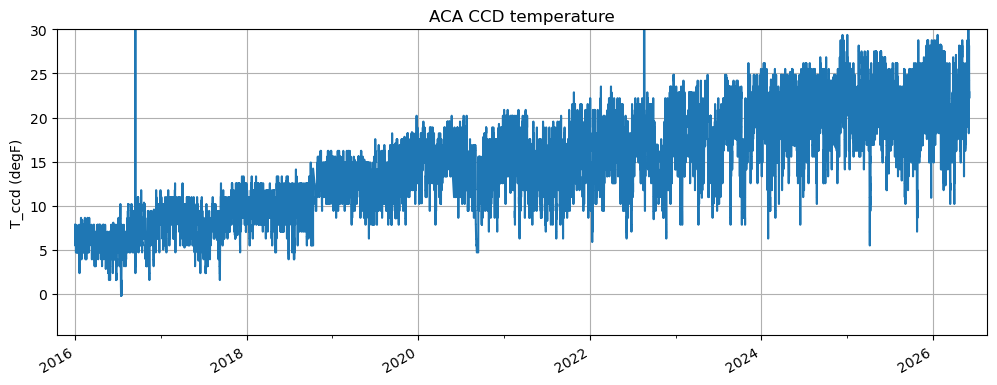

In [3]:
ltt_bads = events.ltt_bads(pad=(0, 200000))
normal_suns = events.normal_suns(pad=(0, 100000))
safe_suns = events.safe_suns(pad=(0, 86400 * 7))

# ACA CCD temperature for overview plot
t_ccd_msid = fetch.Msid("aacccdpt", start="2016:001", stat="5min")
t_ccd_msid.remove_intervals(ltt_bads | normal_suns | safe_suns)
plt.figure(figsize=(12, 4.5))
t_ccd_msid.plot()
plt.ylabel("T_ccd (degF)")
plt.title("ACA CCD temperature")
plt.ylim(None, 30)
plt.grid()

In [4]:
# Aspect solution DY and DZ sampled at 1 ksec intervals, updated daily.
if "adat" not in globals():
    with tables.open_file(
        f"{os.environ['SKA']}/data/aimpoint_mon3/aimpoint_asol_values.h5"
    ) as h5:
        adat = h5.root.data[:]
    adat.sort(order=["time"])
    bad = (adat["dy"] == 0.0) & (adat["dz"] == 0.0)
    adat = adat[~bad]

In [5]:
# Observed aimpoints table maintained by a cron job on HEAD.
aim_obs = Table.read(
    f"{os.environ['SKA']}/data/aimpoint_mon3/observed_aimpoints.dat",
    format="ascii.ecsv",
)
aim_obs[0]

aca_dec,aca_offset_y,aca_offset_z,aca_ra,aca_roll,chip_id,chipx,chipy,detector,dr,dx,dy,mean_date,mean_t_ccd,obs_chipx,obs_chipy,obsid,sim_z,sim_z_off,target_dec,target_offset_y,target_offset_z,target_ra,target_roll
float64,float64,float64,float64,float64,int64,float64,float64,str6,float64,float64,float64,str21,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64
86.237265,7.52,0.53,90.690629,67.667283,3,930.2,1009.6,ACIS-I,2.64,2.11,-1.58,2016:242:05:20:07.816,-13.84,621.03,707.94,18286,-233.587434461,0.00,86.239889,-150.0,150.0,89.7625,68.593411


In [6]:
def plot_observed_aimpoints(
    obs_aimpoints, lookback=365, axis="dx", ax=None, markersize=8, alpha=0.5
):
    """Plot observed aimpoint offsets over time."""
    dates = CxoTime(obs_aimpoints["mean_date"])
    years = dates.frac_year
    times = dates.secs
    ok = years > np.max(years) - float(lookback) / 365.25
    obs_aimpoints = obs_aimpoints[ok]
    times = times[ok]

    lolims = {axis: obs_aimpoints[axis] > 15}
    uplims = {axis: obs_aimpoints[axis] < -15}
    obs_aimpoints[axis] = obs_aimpoints[axis].clip(-15, 15)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))

    label = "CHIPX" if axis == "dx" else "CHIPY"
    for det, c in zip(
        ["HRC-I", "HRC-S", "ACIS-S", "ACIS-I"], ["cyan", "magenta", "blue", "red"]
    ):
        offset_ok = (np.abs(obs_aimpoints["target_offset_y"]) < 100) & (
            np.abs(obs_aimpoints["target_offset_z"]) < 100
        )
        det_ok = obs_aimpoints["detector"] == det
        ok = offset_ok & det_ok
        nok = ~offset_ok & det_ok
        lolims_det = lolims[axis] & det_ok
        uplims_det = uplims[axis] & det_ok
        kwargs = dict(
            markeredgecolor="k",
            markeredgewidth=0.5,
            linestyle="",
            markersize=markersize,
            ax=ax,
            markerfacecolor=c,
        )
        if np.count_nonzero(ok):
            plot_cxctime(times[ok], obs_aimpoints[axis][ok], marker=".", alpha=alpha, label=det, **kwargs)
        if np.count_nonzero(nok):
            plot_cxctime(times[nok], obs_aimpoints[axis][nok], marker="*", **kwargs)
        if np.any(lolims_det):
            plot_cxctime(times[lolims_det], obs_aimpoints[axis][lolims_det], marker=".", yerr=1.5, lolims=True, **kwargs)
        if np.any(uplims_det):
            plot_cxctime(times[uplims_det], obs_aimpoints[axis][uplims_det], marker=".", yerr=1.5, uplims=True, **kwargs)
    ax.grid(True)
    ax.set_ylim(-10, 10)
    ax.set_ylabel("Offset (arcsec)")
    ax.set_title(f"Observed aimpoint offsets {label}")
    ax.legend(loc="upper left", fontsize="x-small", framealpha=0.5, numpoints=1)

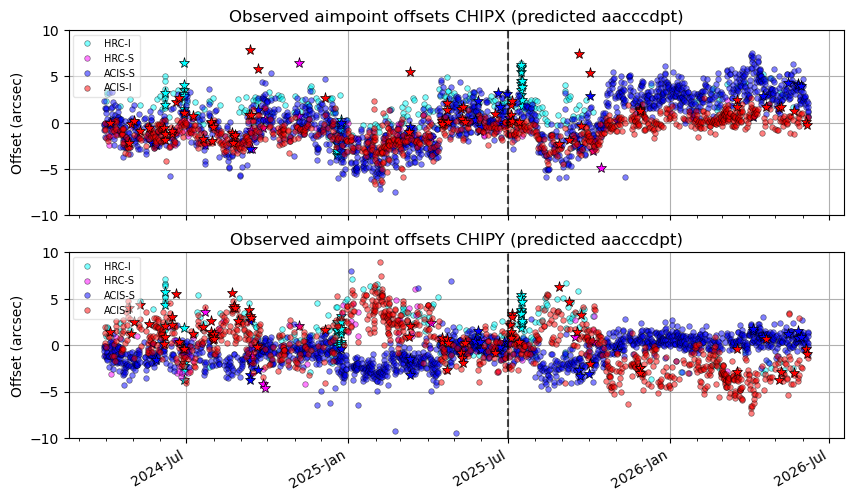

In [7]:
jump_plot_date = CxoTime(NEW_JUMP_DATES[0]).plot_date

_, axes = plt.subplots(2, 1, figsize=(10, 6))
plot_observed_aimpoints(aim_obs, axis="dx", lookback=800, ax=axes[0])
plot_observed_aimpoints(aim_obs, axis="dy", lookback=800, ax=axes[1])
for ax in axes:
    ax.set_title(ax.get_title() + " (predicted aacccdpt)")
    ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)

## Fit classes and functions

## Aimpoint residuals with current flight drift model

Observed ACIS aimpoint offsets corrected using the current flight drift model
evaluated at the actual per-observation telemetered T_ccd.  A persistent
non-zero offset indicates a step change not yet captured by the model.

100%|██████████| 5718/5718 [01:05<00:00, 87.13it/s] 


ACIS-I (n=1983):  mean dx_corr=-0.20 arcsec  mean dy_corr=-1.26 arcsec
ACIS-S (n=3235):  mean dx_corr=+1.30 arcsec  mean dy_corr=-0.18 arcsec
HRC-I (n=339):  mean dx_corr=+2.43 arcsec  mean dy_corr=+0.11 arcsec
HRC-S (n=138):  mean dx_corr=-0.11 arcsec  mean dy_corr=-1.19 arcsec


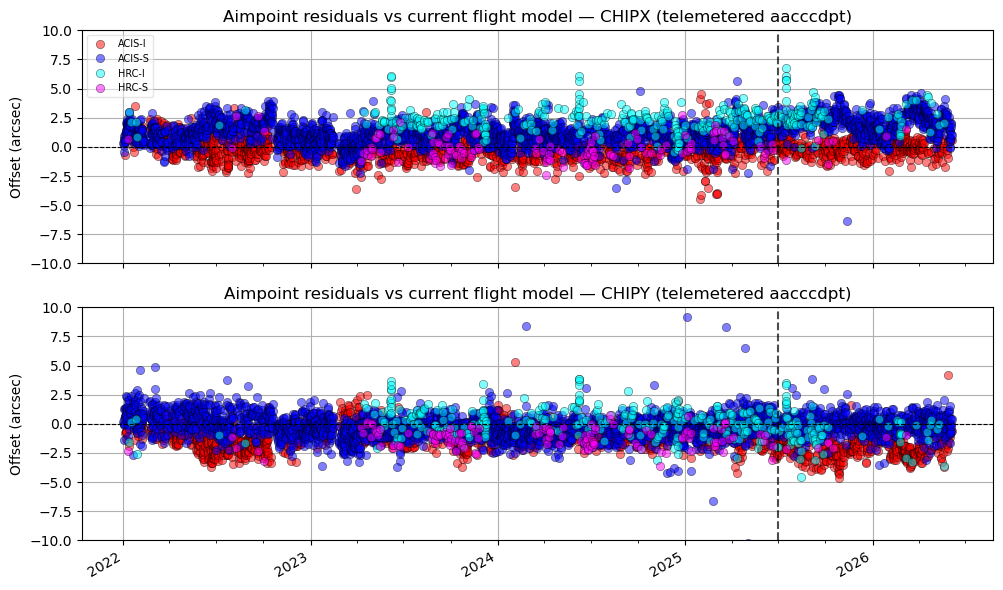

In [8]:
pre_start = CxoTime("2022:001")
pre_stop = CxoTime.now()

ok = (
    (aim_obs["mean_date"] > pre_start.date)
    & (aim_obs["mean_date"] < pre_stop.date)
    & (np.abs(aim_obs["target_offset_y"]) < 100)
    & (np.abs(aim_obs["target_offset_z"]) < 100)
)
obs_pre = aim_obs[ok].copy()

t_ccd_pre = fetch_sci.Msid(
    "aacccdpt",
    start=pre_start - 5 * u.day,
    stop=pre_stop + 5 * u.day,
    stat="5min",
)

obs_pre["dx_corr"] = np.nan
obs_pre["dy_corr"] = np.nan

for obs in tqdm(obs_pre):
    try:
        dwell = events.manvrs.filter(obsid=obs["obsid"])[0]
    except Exception:
        continue
    dwell_tstart = CxoTime(dwell.kalman_start).secs
    dwell_tstop = CxoTime(dwell.next_manvr_start).secs
    i0, i1 = np.searchsorted(t_ccd_pre.times, [dwell_tstart, dwell_tstop])
    if i1 <= i0:
        continue
    mean_t_ccd = np.mean(t_ccd_pre.vals[i0:i1])

    offsets = drift.get_aca_offsets(
        obs["detector"],
        chip_id=obs["chip_id"],
        chipx=obs["chipx"],
        chipy=obs["chipy"],
        time=obs["mean_date"],
        t_ccd=mean_t_ccd,
    )
    ddy = obs["aca_offset_y"] - offsets[0]
    ddz = obs["aca_offset_z"] - offsets[1]

    entry = drift.ASOL_TO_CHIP[(obs["detector"], obs["chip_id"])]
    cyz = np.array(entry["cyz"])
    cyz_inv = np.linalg.inv(cyz)
    arcsec_per_pix = 0.1318 if "HRC" in obs["detector"] else 0.492

    landing_asol = cyz_inv @ np.array([obs["dx"], obs["dy"]]) / arcsec_per_pix * SIM_MM_TO_ARCSEC
    total_asol = np.array([ddy, ddz]) + landing_asol
    chip_corr = cyz @ total_asol / SIM_MM_TO_ARCSEC * arcsec_per_pix
    obs["dx_corr"] = chip_corr[0]
    obs["dy_corr"] = chip_corr[1]

for det in ["ACIS-I", "ACIS-S", "HRC-I", "HRC-S"]:
    ok_det = (
        (obs_pre["detector"] == det)
        & np.isfinite(obs_pre["dx_corr"])
        & (np.abs(obs_pre["dx"]) < 15)
    )
    n = ok_det.sum()
    if n == 0:
        continue
    print(
        f"{det} (n={n}):  "
        f"mean dx_corr={np.mean(obs_pre['dx_corr'][ok_det]):+.2f} arcsec  "
        f"mean dy_corr={np.mean(obs_pre['dy_corr'][ok_det]):+.2f} arcsec"
    )

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
colors = {"ACIS-I": "red", "ACIS-S": "blue", "HRC-I": "cyan", "HRC-S": "magenta"}
ok_plot = np.isfinite(obs_pre["dx_corr"]) & (np.abs(obs_pre["dx"]) < 15)

for det, c in colors.items():
    det_ok = ok_plot & (obs_pre["detector"] == det)
    if not det_ok.sum():
        continue
    times = CxoTime(obs_pre["mean_date"][det_ok]).secs
    for ax, col in zip(axes, ["dx_corr", "dy_corr"]):
        plot_cxctime(
            times, obs_pre[col][det_ok],
            marker="o", markerfacecolor=c, markeredgecolor="k",
            markeredgewidth=0.5, linestyle="", alpha=0.5, label=det, ax=ax,
        )

for ax, label in zip(axes, ["CHIPX", "CHIPY"]):
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
    ax.set_ylim(-10, 10)
    ax.set_ylabel("Offset (arcsec)")
    ax.set_title(f"Aimpoint residuals vs current flight model — {label} (telemetered aacccdpt)")
    ax.grid()

axes[0].legend(loc="upper left", fontsize="x-small", framealpha=0.5, numpoints=1)
plt.tight_layout()

In [9]:
class AcaDriftModel(object):
    """
    Sherpa user model for ACA alignment drift.

    Initialized with ASOL data and CCD temperature telemetry; called by Sherpa
    with parameter arrays during fitting.
    """

    def __init__(self, adat, axis, pars, start="2012:001", stop=None):
        self.pars = pars
        self.axis = axis
        self.name = f"aca_drift_model_{axis}"

        t_ccd = fetch.Msid("aacccdpt", stat="5min", start=start, stop=stop)

        i0, i1 = np.searchsorted(adat["time"], [t_ccd.times[0], t_ccd.times[-1]])
        self.asol = adat[i0:i1].copy()
        self.asol["dy"] *= SIM_MM_TO_ARCSEC
        self.asol["dz"] *= SIM_MM_TO_ARCSEC

        self.times = self.asol["time"]
        self.years = CxoTime(self.times, format="cxcsec").decimalyear
        self.t_ccd = interpolate(t_ccd.vals, t_ccd.times, self.asol["time"], method="linear")

        jump_dates = [jump[0] for jump in self.pars["jumps"]]
        self.jump_times = CxoTime(jump_dates).secs
        self.jump_idxs = np.searchsorted(self.times, self.jump_times)

    @property
    def model(self):
        return globals()[self.name]

    @property
    def parvals(self):
        return [par.val for par in self.model.pars]

    def __call__(self, pars, years=None, t_ccd=None):
        if years is None:
            years = self.years
        if t_ccd is None:
            t_ccd = self.t_ccd

        year0, scale, offset, trend = pars[:4]
        jumps = pars[4:]

        out = (t_ccd - offset) * scale + (years - year0) * trend
        for jump_idx, jump in zip(self.jump_idxs, jumps):
            if 10 < jump_idx < len(out) - 10:
                out[jump_idx:] += jump
        return out

In [10]:
def convert_json_pars_to_sherpa_pars(json_pars):
    sherpa_pars = {name: json_pars[name] for name in ("year0", "scale", "offset", "trend")}
    for date, parval in json_pars["jumps"]:
        sherpa_pars[f"jump{date.replace(':', '')}"] = parval
    return sherpa_pars


def get_aca_drift_model(
    pars_prev: dict,
    axis: str = "dy",
    start: str = "2012:180",
    stop: Optional[str] = None,
    new_jump_dates: Optional[List[str]] = None,
):
    """Create Sherpa user model for ACA drift, freezing all previous parameters."""
    pars_sherpa_prev = convert_json_pars_to_sherpa_pars(pars_prev)

    pars = pars_prev.copy()
    pars["jumps"] = list(pars["jumps"])  # ensure mutable
    for date in (new_jump_dates or []):
        pars["jumps"].append((date, 0.0))

    pars_sherpa = convert_json_pars_to_sherpa_pars(pars)
    aca_drift = AcaDriftModel(adat, axis, pars, start=start, stop=stop)

    ui.load_user_model(aca_drift, aca_drift.name)
    ui.add_user_pars(aca_drift.name, list(pars_sherpa))

    for name, val in pars_sherpa_prev.items():
        par = getattr(aca_drift.model, name)
        par.val = val
        par.freeze()

    return aca_drift


def fit_aimpoint_aca_temp(aca_drift):
    """Fit unfrozen parameters with Sherpa Simplex minimization."""
    dyz = aca_drift.asol[aca_drift.axis]
    ui.load_arrays(1, aca_drift.years, dyz)
    ui.set_model(1, aca_drift.model)
    ui.set_method("simplex")
    ui.fit(1)
    return ui.get_fit_results()


def plot_aimpoint_drift(
    axis, aca_drift, start="2010:001", stop=None, ax=None,
    color="C0", alpha=1.0, label=None,
):
    """Plot fit residuals (data minus model) vs time. Returns (times, residuals)."""
    stop = stop or CxoTime.now().date
    y_start = CxoTime(start).frac_year
    y_stop = CxoTime(stop).frac_year
    years = aca_drift.years
    ok = (years > y_start) & (years < y_stop)
    times = aca_drift.times[ok]

    pars = [par.val for par in aca_drift.model.pars]
    dyz_fit = aca_drift(pars)[ok]
    dyz = aca_drift.asol[axis][ok]
    dyz_resid = dyz - dyz_fit

    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(10, 6))

    plot_cxctime(times, dyz_resid, ",", color=color, alpha=alpha, label=label, ax=ax)
    ax.set_title(f"Fit residuals: aspect solution {axis.upper()} vs model")
    ax.set_ylabel(f"{axis.upper()} (arcsec)")
    ax.grid(True)

    p1, p99 = np.percentile(dyz_resid, [1, 99])
    print(f"Fit residual stddev = {dyz_resid.std():.2f} arcsec")
    print(f"Fit residual 99th - 1st percentile = {p99 - p1:.2f} arcsec")

    return times, dyz_resid

## Load flight drift parameters

In [11]:
txt, info = chandra_models.get_data("chandra_models/aca_drift/aca_drift_model.json")
pars_flight = json.loads(txt)
print(f"Flight model version: {info['version']}")
pars_flight

Flight model version: 3.74.0


{'dy': {'year0': 2016.0,
  'scale': 2.1467,
  'offset': -6.012,
  'trend': -1.108,
  'jumps': [['2015:006', -4.6],
   ['2015:265', -4.669],
   ['2016:064', -1.793],
   ['2017:066', -1.725],
   ['2018:285', -12.505],
   ['2022:294', -7.966],
   ['2023:048', -3.5379],
   ['2024:001', 0.6935]]},
 'dz': {'year0': 2016.0,
  'scale': 1.004,
  'offset': -15.963,
  'trend': -0.159,
  'jumps': [['2015:006', -2.109],
   ['2015:265', -0.368],
   ['2016:064', -0.902],
   ['2017:066', -0.856],
   ['2018:285', -6.056],
   ['2022:294', -1.5133],
   ['2023:048', -1.7357],
   ['2024:001', 0.3968]]}}

## Fit DY

In [12]:
aca_drift_dy = get_aca_drift_model(
    axis="dy", pars_prev=pars_flight["dy"], new_jump_dates=NEW_JUMP_DATES
)
print(f"Data through: {CxoTime(aca_drift_dy.times[-1]).date}")

Data through: 2026:155:20:42:02.648


Fit residual stddev = 1.01 arcsec
Fit residual 99th - 1st percentile = 4.68 arcsec


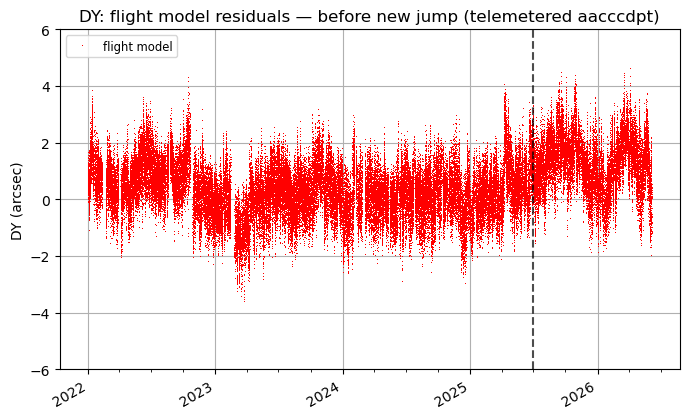

In [13]:
# Residuals with flight model before fitting new jump
_, ax = plt.subplots(figsize=(8, 5))
times_pre_dy, resid_pre_dy = plot_aimpoint_drift(
    "dy", aca_drift_dy, start="2022:001", ax=ax, color="red", label="flight model"
)
ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
ax.set_ylim(-6, 6)
ax.set_title("DY: flight model residuals — before new jump (telemetered aacccdpt)")
ax.legend(loc="upper left", fontsize="small")

In [14]:
fit_dy = fit_aimpoint_aca_temp(aca_drift_dy)

Dataset               = 1
Method                = neldermead
Statistic             = chi2gehrels
Initial fit statistic = 20498.1
Final fit statistic   = 16829.5 at function evaluation 112
Data points           = 331575
Degrees of freedom    = 331574
Probability [Q-value] = 1
Reduced statistic     = 0.0507565
Change in statistic   = 3668.56
   aca_drift_model_dy.jump2025182   1.40897     


### Optional: manually override DY jump instead of using fit result

In [15]:
# Uncomment to override the fitted DY jump with a manual value.
# This freezes the parameter so write_drift_pars picks it up correctly.

# jump_name = f"jump{NEW_JUMP_DATES[0].replace(':', '')}"
# getattr(aca_drift_dy.model, jump_name).val = 2.0
# getattr(aca_drift_dy.model, jump_name).freeze()

Fit residual stddev = 0.94 arcsec
Fit residual 99th - 1st percentile = 4.47 arcsec


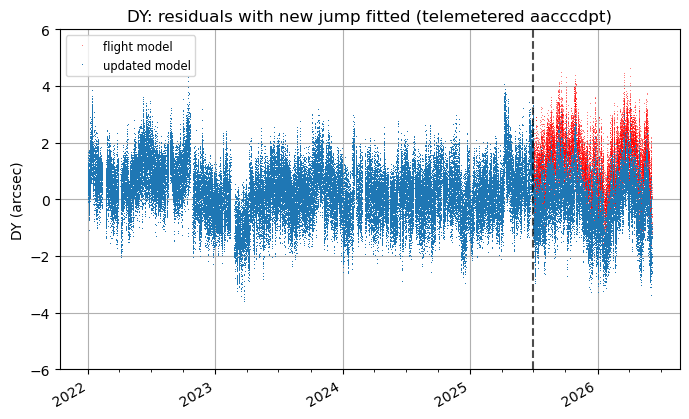

In [16]:
# Residuals after fitting new jump, with flight model residuals overlaid
_, ax = plt.subplots(figsize=(8, 5))
plot_cxctime(times_pre_dy, resid_pre_dy, ",", color="red", alpha=0.5, label="flight model", ax=ax)
plot_aimpoint_drift(
    "dy", aca_drift_dy, start="2022:001", ax=ax, color="C0", label="updated model"
)
ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
ax.set_ylim(-6, 6)
ax.set_title("DY: residuals with new jump fitted (telemetered aacccdpt)")
ax.legend(loc="upper left", fontsize="small")

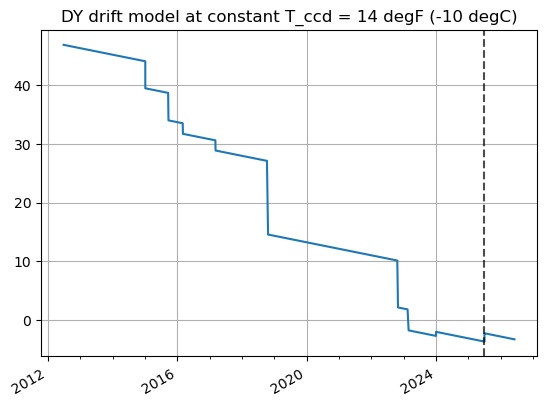

In [17]:
dyz_fit = aca_drift_dy(aca_drift_dy.parvals, t_ccd=14)  # degF = -10 C
plot_cxctime(aca_drift_dy.times, dyz_fit)
plt.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
plt.title("DY drift model at constant T_ccd = 14 degF (-10 degC)")
plt.grid()

## Fit DZ

In [18]:
aca_drift_dz = get_aca_drift_model(
    axis="dz", pars_prev=pars_flight["dz"], new_jump_dates=NEW_JUMP_DATES
)

Fit residual stddev = 0.92 arcsec
Fit residual 99th - 1st percentile = 4.54 arcsec


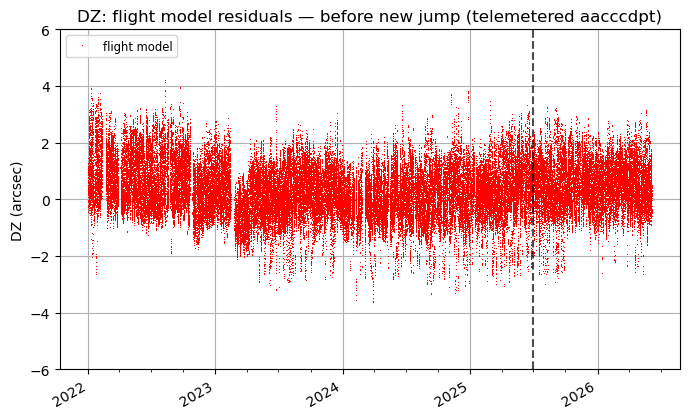

In [19]:
# Residuals with flight model before fitting new jump
_, ax = plt.subplots(figsize=(8, 5))
times_pre_dz, resid_pre_dz = plot_aimpoint_drift(
    "dz", aca_drift_dz, start="2022:001", ax=ax, color="red", label="flight model"
)
ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
ax.set_ylim(-6, 6)
ax.set_title("DZ: flight model residuals — before new jump (telemetered aacccdpt)")
ax.legend(loc="upper left", fontsize="small")

In [20]:
fit_dz = fit_aimpoint_aca_temp(aca_drift_dz)

Dataset               = 1
Method                = neldermead
Statistic             = chi2gehrels
Initial fit statistic = 18997.6
Final fit statistic   = 18848.5 at function evaluation 113
Data points           = 331575
Degrees of freedom    = 331574
Probability [Q-value] = 1
Reduced statistic     = 0.0568456
Change in statistic   = 149.042
   aca_drift_model_dz.jump2025182   0.470317    


### Optional: manually override DZ jump instead of using fit result

In [21]:
# Uncomment to override the fitted DZ jump with a manual value.
# This freezes the parameter so write_drift_pars picks it up correctly.

# jump_name = f"jump{NEW_JUMP_DATES[0].replace(':', '')}"
# getattr(aca_drift_dz.model, jump_name).val = 0.5
# getattr(aca_drift_dz.model, jump_name).freeze()

Fit residual stddev = 0.92 arcsec
Fit residual 99th - 1st percentile = 4.55 arcsec


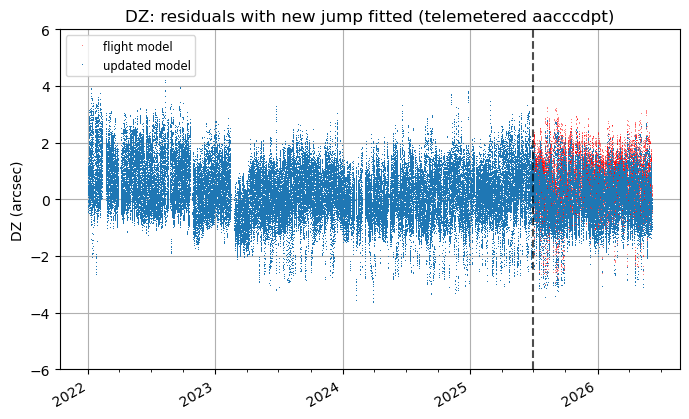

In [22]:
# Residuals after fitting new jump, with flight model residuals overlaid
_, ax = plt.subplots(figsize=(8, 5))
plot_cxctime(times_pre_dz, resid_pre_dz, ",", color="red", alpha=0.5, label="flight model", ax=ax)
plot_aimpoint_drift(
    "dz", aca_drift_dz, start="2022:001", ax=ax, color="C0", label="updated model"
)
ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
ax.set_ylim(-6, 6)
ax.set_title("DZ: residuals with new jump fitted (telemetered aacccdpt)")
ax.legend(loc="upper left", fontsize="small")

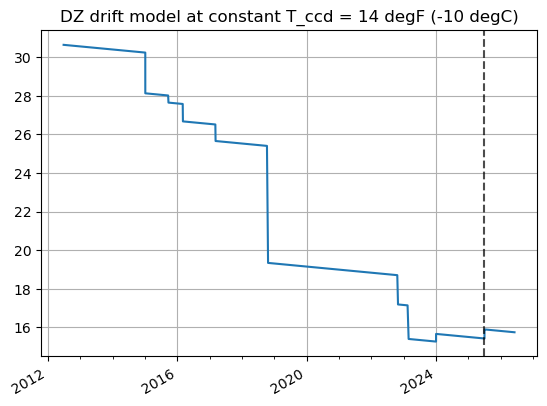

In [23]:
dyz_fit = aca_drift_dz(aca_drift_dz.parvals, t_ccd=14)
plot_cxctime(aca_drift_dz.times, dyz_fit)
plt.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
plt.title("DZ drift model at constant T_ccd = 14 degF (-10 degC)")
plt.grid()

## Write updated parameters

The jump is fitted at `2025:182` for validation purposes.  The validation section
below uses these fit-date parameters so that observations since `2025:182` show the
correction.  The deployed model (with the jump date remapped to `2026:161`) is written
to `aca_drift_model.json` after validation.

This file can then be installed in a branch of `chandra_models`:
```bash
cd ~/git/chandra_models
git switch master && git pull
git switch -c aimpoint-drift-update
cp ~/git/aimpoint_mon/aca_drift_model.json chandra_models/aca_drift/
git add chandra_models/aca_drift/aca_drift_model.json
git commit -m "Update aimpoint drift model 2026-06"
```

In [24]:
def build_drift_pars(aca_drift_dy, aca_drift_dz, date_map=None):
    """Build drift parameters dict from fitted Sherpa models.

    date_map remaps jump dates, e.g. {"2025:182": "2026:161"} for deployment.
    """
    pars = {}
    for axis, aca_drift in (("dy", aca_drift_dy), ("dz", aca_drift_dz)):
        pars[axis] = {}
        jumps = []
        for par in aca_drift.model.pars:
            name = par.name.replace(f"{aca_drift.name}.", "")
            val = round(par.val, 4)
            if name.startswith("jump"):
                date = name[4:8] + ":" + name[8:]
                if date_map:
                    date = date_map.get(date, date)
                jumps.append([date, val])
            else:
                pars[axis][name] = val
        pars[axis]["jumps"] = jumps
    return pars


def write_drift_pars(path, aca_drift_dy, aca_drift_dz, date_map=None):
    pars = build_drift_pars(aca_drift_dy, aca_drift_dz, date_map=date_map)
    with open(path, "w") as fh:
        json.dump(pars, fh, indent=4)
    return pars

In [25]:
# Build validation parameters using the fit date (2025:182) so the correction
# is visible in the validation plots below.
aca_drift_pars = build_drift_pars(aca_drift_dy, aca_drift_dz)
aca_drift_pars

{'dy': {'year0': np.float64(2016.0),
  'scale': np.float64(2.1467),
  'offset': np.float64(-6.012),
  'trend': np.float64(-1.108),
  'jumps': [['2015:006', np.float64(-4.6)],
   ['2015:265', np.float64(-4.669)],
   ['2016:064', np.float64(-1.793)],
   ['2017:066', np.float64(-1.725)],
   ['2018:285', np.float64(-12.505)],
   ['2022:294', np.float64(-7.966)],
   ['2023:048', np.float64(-3.5379)],
   ['2024:001', np.float64(0.6935)],
   ['2025:182', np.float64(1.409)]]},
 'dz': {'year0': np.float64(2016.0),
  'scale': np.float64(1.004),
  'offset': np.float64(-15.963),
  'trend': np.float64(-0.159),
  'jumps': [['2015:006', np.float64(-2.109)],
   ['2015:265', np.float64(-0.368)],
   ['2016:064', np.float64(-0.902)],
   ['2017:066', np.float64(-0.856)],
   ['2018:285', np.float64(-6.056)],
   ['2022:294', np.float64(-1.5133)],
   ['2023:048', np.float64(-1.7357)],
   ['2024:001', np.float64(0.3968)],
   ['2025:182', np.float64(0.4703)]]}}

## Validate: observed aimpoints corrected with new model

Apply the fitted drift model (via `drift_pars` kwarg — no `chandra_models` branch required)
at the actual per-observation telemetered T_ccd and compare to the flight model residuals.

In [26]:
corr_start = CxoTime("2022:001")
corr_stop = CxoTime.now()

ok = (
    (aim_obs["mean_date"] > corr_start.date)
    & (aim_obs["mean_date"] < corr_stop.date)
    & (np.abs(aim_obs["target_offset_y"]) < 100)
    & (np.abs(aim_obs["target_offset_z"]) < 100)
)
obs_recents = aim_obs[ok].copy()
print(f"{len(obs_recents)} observations from {corr_start.date} to {corr_stop.date}")

5718 observations from 2022:001:00:00:00.000 to 2026:163:15:56:39.247


In [27]:
t_ccd_corr = fetch_sci.Msid(
    "aacccdpt",
    start=corr_start - 5 * u.day,
    stop=corr_stop + 5 * u.day,
    stat="5min",
)

obs_recents["dx_corr"] = np.nan
obs_recents["dy_corr"] = np.nan

for obs in tqdm(obs_recents):
    try:
        dwell = events.manvrs.filter(obsid=obs["obsid"])[0]
    except Exception:
        continue
    dwell_tstart = CxoTime(dwell.kalman_start).secs
    dwell_tstop = CxoTime(dwell.next_manvr_start).secs
    i0, i1 = np.searchsorted(t_ccd_corr.times, [dwell_tstart, dwell_tstop])
    if i1 <= i0:
        continue
    mean_t_ccd = np.mean(t_ccd_corr.vals[i0:i1])

    offsets = drift.get_aca_offsets(
        obs["detector"],
        chip_id=obs["chip_id"],
        chipx=obs["chipx"],
        chipy=obs["chipy"],
        time=obs["mean_date"],
        t_ccd=mean_t_ccd,
        drift_pars=aca_drift_pars,
    )
    ddy = obs["aca_offset_y"] - offsets[0]
    ddz = obs["aca_offset_z"] - offsets[1]

    entry = drift.ASOL_TO_CHIP[(obs["detector"], obs["chip_id"])]
    cyz = np.array(entry["cyz"])
    cyz_inv = np.linalg.inv(cyz)
    arcsec_per_pix = 0.1318 if "HRC" in obs["detector"] else 0.492

    landing_asol = cyz_inv @ np.array([obs["dx"], obs["dy"]]) / arcsec_per_pix * SIM_MM_TO_ARCSEC
    total_asol = np.array([ddy, ddz]) + landing_asol
    chip_corr = cyz @ total_asol / SIM_MM_TO_ARCSEC * arcsec_per_pix
    obs["dx_corr"] = chip_corr[0]
    obs["dy_corr"] = chip_corr[1]

100%|██████████| 5718/5718 [01:08<00:00, 83.79it/s]


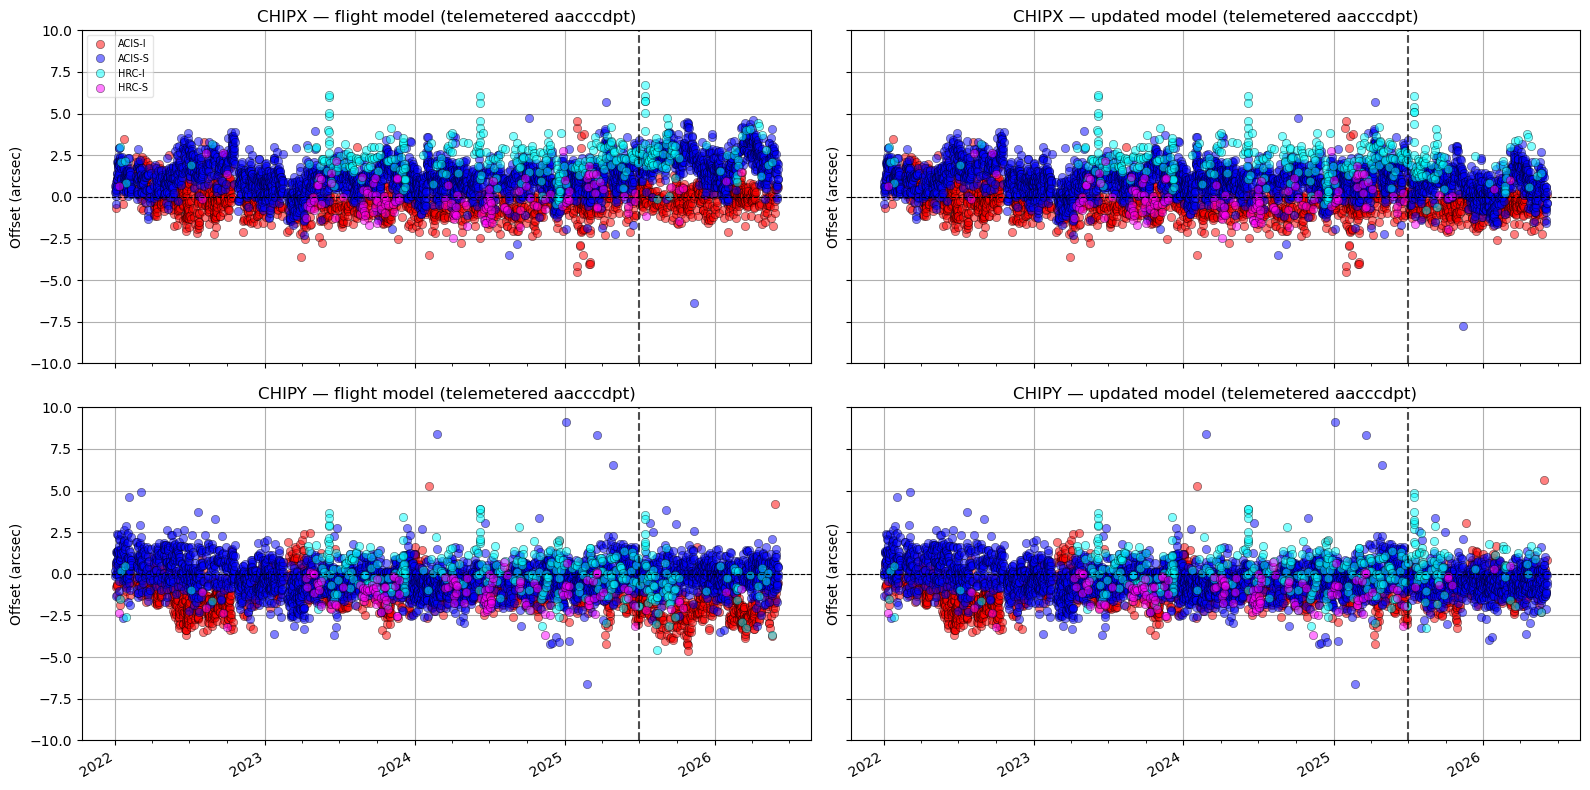

In [28]:
colors = {"ACIS-I": "red", "ACIS-S": "blue", "HRC-I": "cyan", "HRC-S": "magenta"}

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey="row")
axes[0, 0].set_title("CHIPX — flight model (telemetered aacccdpt)")
axes[0, 1].set_title("CHIPX — updated model (telemetered aacccdpt)")
axes[1, 0].set_title("CHIPY — flight model (telemetered aacccdpt)")
axes[1, 1].set_title("CHIPY — updated model (telemetered aacccdpt)")

for col_idx, obs_data in enumerate([obs_pre, obs_recents]):
    ok_plot = np.isfinite(obs_data["dx_corr"]) & (np.abs(obs_data["dx"]) < 15)
    for det, c in colors.items():
        det_ok = ok_plot & (obs_data["detector"] == det)
        if not det_ok.sum():
            continue
        times = CxoTime(obs_data["mean_date"][det_ok]).secs
        for row_idx, col in enumerate(["dx_corr", "dy_corr"]):
            ax = axes[row_idx, col_idx]
            plot_cxctime(
                times, obs_data[col][det_ok],
                marker="o", markerfacecolor=c, markeredgecolor="k",
                markeredgewidth=0.5, linestyle="", alpha=0.5, label=det, ax=ax,
            )

for ax in axes.flat:
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.axvline(jump_plot_date, color="k", lw=1.5, ls="--", alpha=0.7)
    ax.set_ylim(-10, 10)
    ax.set_ylabel("Offset (arcsec)")
    ax.grid()

axes[0, 0].legend(loc="upper left", fontsize="x-small", framealpha=0.5, numpoints=1)
plt.tight_layout()

### Zoomed: 2025:182 to present

Close-up view around the new jump date with a tighter y-axis scale.

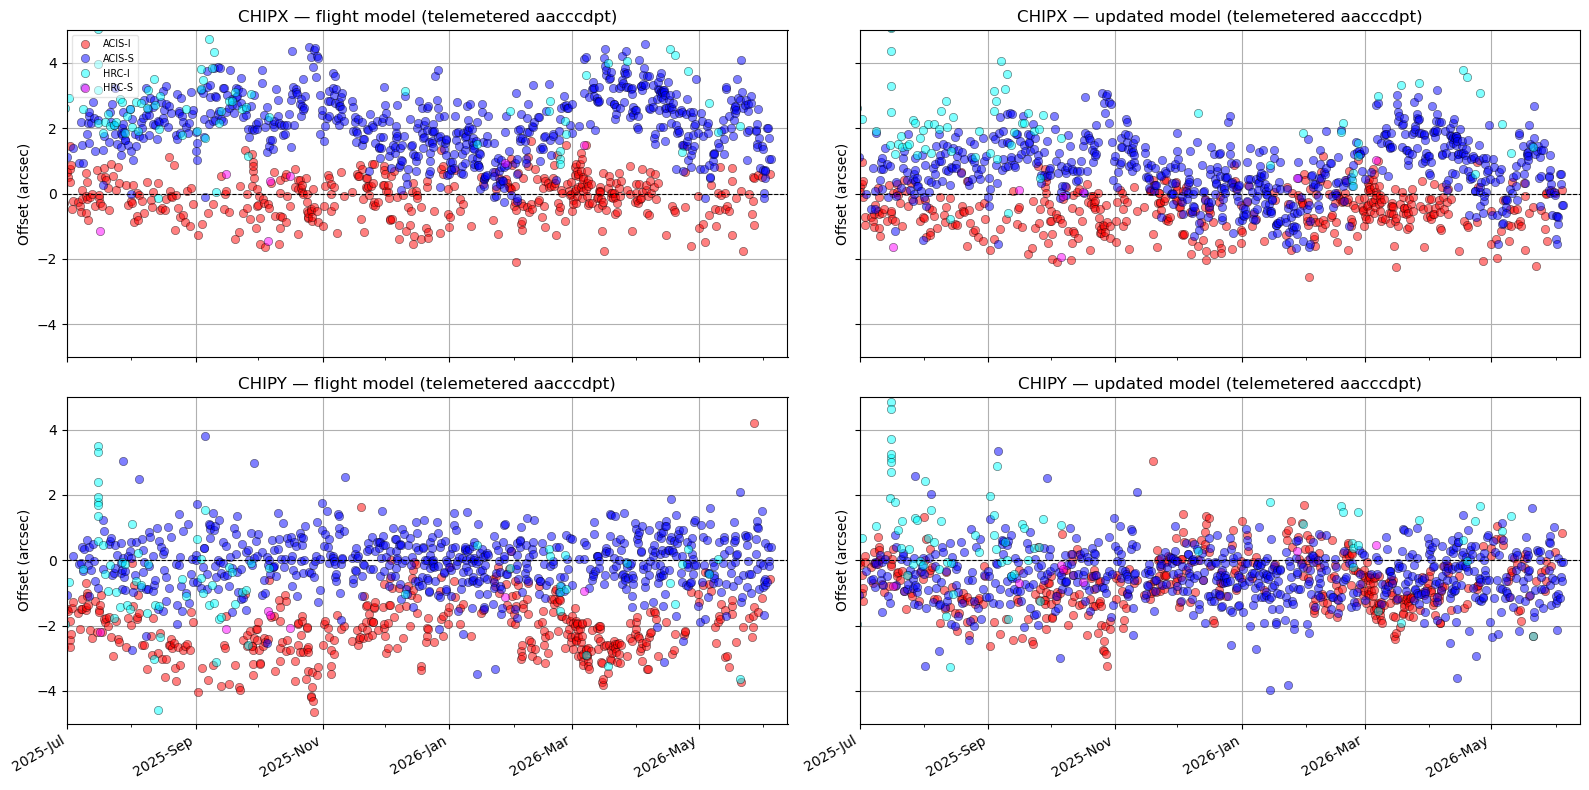

In [29]:
zoom_start = CxoTime(NEW_JUMP_DATES[0]).plot_date
zoom_stop = CxoTime.now().plot_date

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey="row")
axes[0, 0].set_title("CHIPX — flight model (telemetered aacccdpt)")
axes[0, 1].set_title("CHIPX — updated model (telemetered aacccdpt)")
axes[1, 0].set_title("CHIPY — flight model (telemetered aacccdpt)")
axes[1, 1].set_title("CHIPY — updated model (telemetered aacccdpt)")

for col_idx, obs_data in enumerate([obs_pre, obs_recents]):
    ok_plot = np.isfinite(obs_data["dx_corr"]) & (np.abs(obs_data["dx"]) < 15)
    for det, c in colors.items():
        det_ok = ok_plot & (obs_data["detector"] == det)
        if not det_ok.sum():
            continue
        times = CxoTime(obs_data["mean_date"][det_ok]).secs
        for row_idx, col in enumerate(["dx_corr", "dy_corr"]):
            ax = axes[row_idx, col_idx]
            plot_cxctime(
                times, obs_data[col][det_ok],
                marker="o", markerfacecolor=c, markeredgecolor="k",
                markeredgewidth=0.5, linestyle="", alpha=0.5, label=det, ax=ax,
            )

for ax in axes.flat:
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_xlim(zoom_start, zoom_stop)
    ax.set_ylim(-5, 5)
    ax.set_ylabel("Offset (arcsec)")
    ax.grid()

axes[0, 0].legend(loc="upper left", fontsize="x-small", framealpha=0.5, numpoints=1)
plt.tight_layout()

## Regression data

Write regression data for `chandra_aca/chandra_aca/tests/data/aimpoint_regression_data.ecsv`.

This is not impacting for this new step (set to start next week) but we're leaving the code in the notebook for future updates.

In [30]:
def make_regression_data(aim_obs: Table) -> Table:
    """Make regression data using the planned aimpoint offsets from flight products.

    This pulls the first observation of the year for each detector.

    Of note is that prior to 2019 the aimpoint model was refit for all parameters so
    we do not expect an exact match. From 2018-11 forward we expect a match to within
    the reported precision (0.01 arcsec) for all historical data after 2018-11.
    """
    year_now = CxoTime.now().decimalyear.astype(int)
    rows = []
    for year in range(2019, year_now + 1):
        mean_dates_year = np.trunc(CxoTime(aim_obs["mean_date"]).decimalyear)
        for detector in ("ACIS-I", "ACIS-S", "HRC-I", "HRC-S"):
            ok = (mean_dates_year == year) & (aim_obs["detector"] == detector)
            idx = np.where(ok)[0][0]
            rows.append(aim_obs[idx])
    out = Table(rows=rows, names=aim_obs.colnames)
    for name in ("dx", "dy", "dr", "obs_chipx", "obs_chipy", "sim_z_off"):
        out[name] = np.round(out[name], 2)
    return out

In [31]:
regr_data = make_regression_data(aim_obs)
regr_data

aca_dec,aca_offset_y,aca_offset_z,aca_ra,aca_roll,chip_id,chipx,chipy,detector,dr,dx,dy,mean_date,mean_t_ccd,obs_chipx,obs_chipy,obsid,sim_z,sim_z_off,target_dec,target_offset_y,target_offset_z,target_ra,target_roll
float64,float64,float64,float64,float64,int64,float64,float64,str6,float64,float64,float64,str21,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64
34.160086,-7.77,-18.87,84.074467,240.0003,3,970.0,975.0,ACIS-I,0.77,0.38,-0.67,2019:001:02:27:50.816,-10.03,969.22,976.36,22032,-233.587434461,0.0,34.14,0.0,0.0,84.075,240.0
-12.02966,4.95,-19.94,97.515608,352.757411,7,210.0,520.0,ACIS-S,1.71,1.11,1.3,2019:002:05:28:42.816,-9.7,207.75,517.47,21445,-190.142580365,0.05,-12.022222,0.0,0.0,97.537917,352.762058
-54.648561,1.17,-15.99,0.404521,258.989754,0,7590.0,7745.0,HRC-I,1.17,0.96,-0.66,2019:021:19:53:06.816,-11.75,7582.69,7750.03,21717,126.98297999,0.0,-54.67,0.0,0.0,0.417083,259.0
-69.249784,-1.94,-17.69,83.843007,262.977874,2,2195.0,8915.0,HRC-S,1.48,0.06,-1.48,2019:078:13:18:46.816,-10.67,2194.55,8926.21,21303,250.46603308,-0.0,-69.26975,0.0,0.0,83.866667,263.0
-5.03607,-3.2,-17.1,96.962943,341.766549,3,970.0,975.0,ACIS-I,0.21,-0.2,-0.05,2020:006:09:45:38.816,-10.92,970.41,975.11,22895,-233.587434461,0.0,-5.031472,0.0,0.0,96.983958,341.768392
-2.164788,3.48,-20.98,335.951787,296.169313,7,210.0,520.0,ACIS-S,2.25,0.86,2.08,2020:001:00:01:06.816,-9.03,208.24,515.78,21507,-190.14006605,-0.0,-2.178667,0.0,0.0,335.969583,296.169986
5.215619,-8.37,-20.81,114.80178,339.562135,0,7590.0,7745.0,HRC-I,2.57,2.23,-1.28,2020:019:15:14:14.816,-9.0,7573.09,7754.71,21579,126.98297999,0.0,5.218944,0.0,0.0,114.82125,339.560364
32.837213,-8.47,-21.06,122.245746,212.553259,2,2195.0,8915.0,HRC-S,3.54,0.06,-3.54,2020:030:08:29:22.816,-8.73,2194.56,8941.85,23137,250.46603308,-0.0,32.819801,0.0,0.0,122.235001,212.559084
-41.278512,-7.95,-19.67,131.170759,28.107706,3,970.0,975.0,ACIS-I,0.43,0.02,-0.43,2021:002:05:03:34.816,-9.41,969.96,975.87,22689,-233.587434461,0.0,-41.261444,0.0,0.0,131.184458,28.116742


In [32]:
# Write out regression data for installation in
# chandra_aca/chandra_aca/tests/data/aimpoint_regression_data.ecsv
regr_data.write("aimpoint_regression_data.ecsv", format="ascii.ecsv", overwrite=True)
!cat aimpoint_regression_data.ecsv

# %ECSV 1.0
# ---
# datatype:
# - {name: aca_dec, datatype: float64}
# - {name: aca_offset_y, datatype: float64}
# - {name: aca_offset_z, datatype: float64}
# - {name: aca_ra, datatype: float64}
# - {name: aca_roll, datatype: float64}
# - {name: chip_id, datatype: int64}
# - {name: chipx, datatype: float64}
# - {name: chipy, datatype: float64}
# - {name: detector, datatype: string}
# - {name: dr, datatype: float64}
# - {name: dx, datatype: float64}
# - {name: dy, datatype: float64}
# - {name: mean_date, datatype: string}
# - {name: mean_t_ccd, datatype: float64}
# - {name: obs_chipx, datatype: float64}
# - {name: obs_chipy, datatype: float64}
# - {name: obsid, datatype: int64}
# - {name: sim_z, datatype: float64}
# - {name: sim_z_off, datatype: float64}
# - {name: target_dec, datatype: float64}
# - {name: target_offset_y, datatype: float64}
# - {name: target_offset_z, datatype: float64}
# - {name: target_ra, datatype: float64}
# - {name: target_roll, datatype: float64}
# schema: astrop

## Write deploy model

Write `aca_drift_model.json` with the jump date remapped from `2025:182` to
`2026:161` for deployment.  This is done after validation so the validation plots
above use the fit date and correctly show the correction for post-`2025:182`
observations.

In [33]:
aca_drift_pars_deploy = write_drift_pars(
    "aca_drift_model.json",
    aca_drift_dy,
    aca_drift_dz,
    date_map={NEW_JUMP_DATES[0]: DEPLOY_JUMP_DATE},
)
aca_drift_pars_deploy

{'dy': {'year0': np.float64(2016.0),
  'scale': np.float64(2.1467),
  'offset': np.float64(-6.012),
  'trend': np.float64(-1.108),
  'jumps': [['2015:006', np.float64(-4.6)],
   ['2015:265', np.float64(-4.669)],
   ['2016:064', np.float64(-1.793)],
   ['2017:066', np.float64(-1.725)],
   ['2018:285', np.float64(-12.505)],
   ['2022:294', np.float64(-7.966)],
   ['2023:048', np.float64(-3.5379)],
   ['2024:001', np.float64(0.6935)],
   ['2026:161', np.float64(1.409)]]},
 'dz': {'year0': np.float64(2016.0),
  'scale': np.float64(1.004),
  'offset': np.float64(-15.963),
  'trend': np.float64(-0.159),
  'jumps': [['2015:006', np.float64(-2.109)],
   ['2015:265', np.float64(-0.368)],
   ['2016:064', np.float64(-0.902)],
   ['2017:066', np.float64(-0.856)],
   ['2018:285', np.float64(-6.056)],
   ['2022:294', np.float64(-1.5133)],
   ['2023:048', np.float64(-1.7357)],
   ['2024:001', np.float64(0.3968)],
   ['2026:161', np.float64(0.4703)]]}}